In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    r"Support_Ticket_Dataset.csv"
)

df.head()

,Ticket_ID,Ticket_Text,Category,Priority
0,TKT0001,Payment failed but money was deducted from my ...,Payment,High
1,TKT0002,I was charged twice for the same order,Payment,High
2,TKT0003,My UPI transaction is pending and amount is de...,Payment,High
3,TKT0004,The payment page shows an error after I paid,Payment,High
4,TKT0005,Please check my missing payment confirmation,Payment,Medium


In [4]:
print("Dataset Shape:", df.shape)

df.info()

print("\nColumns:", df.columns.tolist())

Dataset Shape: (120, 4)
<class 'pandas.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Ticket_ID    120 non-null    str  
 1   Ticket_Text  120 non-null    str  
 2   Category     120 non-null    str  
 3   Priority     120 non-null    str  
dtypes: str(4)
memory usage: 11.8 KB

Columns: ['Ticket_ID', 'Ticket_Text', 'Category', 'Priority']


In [5]:
df.isnull().sum()

Ticket_ID      0
Ticket_Text    0
Category       0
Priority       0
dtype: int64

In [6]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


In [7]:
print("Category Distribution:")
print(df["Category"].value_counts())

print("\nPriority Distribution:")
print(df["Priority"].value_counts())

Category Distribution:
Category
Payment      20
Refund       20
Technical    20
Account      20
Shipping     20
Product      20
Name: count, dtype: int64

Priority Distribution:
Priority
High      56
Medium    34
Low       30
Name: count, dtype: int64


In [8]:
import re

def clean_text(text):
    text = text.lower()                  # Convert to lowercase
    text = re.sub(r'[^a-z\s]', '', text) # Remove special characters and numbers
    text = re.sub(r'\s+', ' ', text)     # Remove extra spaces
    return text.strip()

df["Cleaned_Text"] = df["Ticket_Text"].apply(clean_text)

df[["Ticket_Text", "Cleaned_Text"]].head(10)

,Ticket_Text,Cleaned_Text
0,Payment failed but money was deducted from my ...,payment failed but money was deducted from my ...
1,I was charged twice for the same order,i was charged twice for the same order
2,My UPI transaction is pending and amount is de...,my upi transaction is pending and amount is de...
3,The payment page shows an error after I paid,the payment page shows an error after i paid
4,Please check my missing payment confirmation,please check my missing payment confirmation
5,How can I download my payment receipt?,how can i download my payment receipt
6,My card payment is not going through,my card payment is not going through
7,The invoice amount is different from the amoun...,the invoice amount is different from the amoun...
8,Can I use another payment method?,can i use another payment method
9,I need help understanding the payment status,i need help understanding the payment status


In [9]:
print("Original Text:")
print(df["Ticket_Text"][0])

print("\nCleaned Text:")
print(df["Cleaned_Text"][0])

Original Text:
Payment failed but money was deducted from my bank account

Cleaned Text:
payment failed but money was deducted from my bank account


In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=1000)

X = tfidf.fit_transform(df["Cleaned_Text"])

print("TF-IDF Shape:", X.shape)

TF-IDF Shape: (120, 194)


In [11]:
y_category = df["Category"]
y_priority = df["Priority"]

print(y_category.head())
print(y_priority.head())

0    Payment
1    Payment
2    Payment
3    Payment
4    Payment
Name: Category, dtype: str
0      High
1      High
2      High
3      High
4    Medium
Name: Priority, dtype: str


In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_category_train, y_category_test = train_test_split(
    X, y_category,
    test_size=0.2,
    random_state=42,
    stratify=y_category
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (96, 194)
Testing data: (24, 194)


In [13]:
X_train_p, X_test_p, y_priority_train, y_priority_test = train_test_split(
    X, y_priority,
    test_size=0.2,
    random_state=42,
    stratify=y_priority
)

print("Priority Training data:", X_train_p.shape)
print("Priority Testing data:", X_test_p.shape)

Priority Training data: (96, 194)
Priority Testing data: (24, 194)


In [16]:
from sklearn.linear_model import LogisticRegression

category_model = LogisticRegression(max_iter=1000)

category_model.fit(X_train, y_category_train)

print("Category Model Training Completed")

Category Model Training Completed


In [17]:
priority_model = LogisticRegression(max_iter=1000)

priority_model.fit(X_train_p, y_priority_train)

print("Priority Model Training Completed")

Priority Model Training Completed


In [18]:
y_category_pred = category_model.predict(X_test)

print("Actual Categories:")
print(y_category_test.head(10).values)

print("\nPredicted Categories:")
print(y_category_pred[:10])

Actual Categories:
<ArrowStringArray>
[   'Refund',  'Shipping',    'Refund', 'Technical',   'Product',   'Account',
   'Payment',   'Account',   'Product',    'Refund']
Length: 10, dtype: str

Predicted Categories:
['Refund' 'Shipping' 'Refund' 'Technical' 'Product' 'Account' 'Payment'
 'Account' 'Product' 'Refund']


In [19]:
y_priority_pred = priority_model.predict(X_test_p)

print("Actual Priorities:")
print(y_priority_test.head(10).values)

print("\nPredicted Priorities:")
print(y_priority_pred[:10])

Actual Priorities:
<ArrowStringArray>
['Low', 'Medium', 'Low', 'Medium', 'High', 'High', 'High', 'High', 'High',
 'Low']
Length: 10, dtype: str

Predicted Priorities:
['Low' 'Medium' 'Low' 'Medium' 'High' 'High' 'High' 'High' 'High' 'Low']


In [20]:
#Model Evaluation

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Category Model Accuracy:",
      accuracy_score(y_category_test, y_category_pred))

print("\nClassification Report:")
print(classification_report(y_category_test, y_category_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_category_test, y_category_pred))

Category Model Accuracy: 0.9166666666666666

Classification Report:
              precision    recall  f1-score   support

     Account       1.00      1.00      1.00         4
     Payment       1.00      0.50      0.67         4
     Product       1.00      1.00      1.00         4
      Refund       1.00      1.00      1.00         4
    Shipping       0.67      1.00      0.80         4
   Technical       1.00      1.00      1.00         4

    accuracy                           0.92        24
   macro avg       0.94      0.92      0.91        24
weighted avg       0.94      0.92      0.91        24


Confusion Matrix:
[[4 0 0 0 0 0]
 [0 2 0 0 2 0]
 [0 0 4 0 0 0]
 [0 0 0 4 0 0]
 [0 0 0 0 4 0]
 [0 0 0 0 0 4]]


In [21]:
print("Priority Model Accuracy:",
      accuracy_score(y_priority_test, y_priority_pred))

print("\nClassification Report:")
print(classification_report(y_priority_test, y_priority_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_priority_test, y_priority_pred))

Priority Model Accuracy: 0.9583333333333334

Classification Report:
              precision    recall  f1-score   support

        High       0.92      1.00      0.96        11
         Low       1.00      1.00      1.00         6
      Medium       1.00      0.86      0.92         7

    accuracy                           0.96        24
   macro avg       0.97      0.95      0.96        24
weighted avg       0.96      0.96      0.96        24


Confusion Matrix:
[[11  0  0]
 [ 0  6  0]
 [ 1  0  6]]


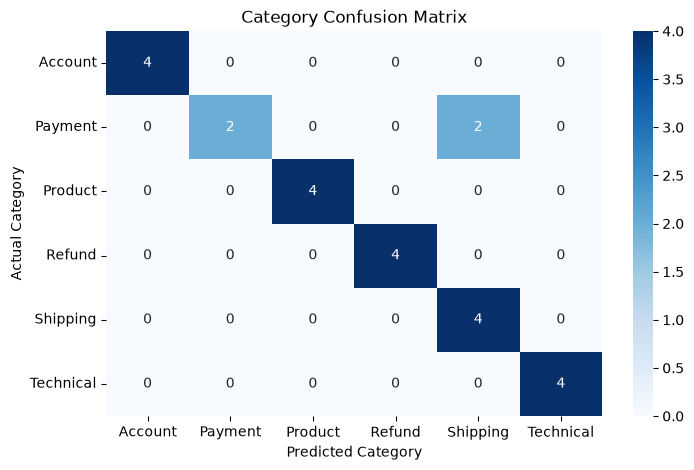

In [22]:
from sklearn.metrics import confusion_matrix

cm_category = confusion_matrix(y_category_test, y_category_pred)

plt.figure(figsize=(8, 5))
sns.heatmap(
    cm_category,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=category_model.classes_,
    yticklabels=category_model.classes_
)

plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.title("Category Confusion Matrix")
plt.show()

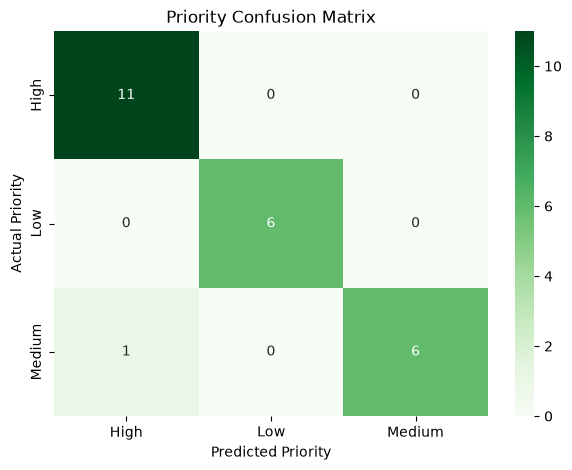

In [23]:
cm_priority = confusion_matrix(y_priority_test, y_priority_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_priority,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=priority_model.classes_,
    yticklabels=priority_model.classes_
)

plt.xlabel("Predicted Priority")
plt.ylabel("Actual Priority")
plt.title("Priority Confusion Matrix")
plt.show()

In [24]:
new_ticket = ["My payment was deducted but my order was not placed"]

cleaned_ticket = [clean_text(new_ticket[0])]

ticket_vector = tfidf.transform(cleaned_ticket)

predicted_category = category_model.predict(ticket_vector)
predicted_priority = priority_model.predict(ticket_vector)

print("Customer Ticket:", new_ticket[0])
print("Predicted Category:", predicted_category[0])
print("Predicted Priority:", predicted_priority[0])

Customer Ticket: My payment was deducted but my order was not placed
Predicted Category: Payment
Predicted Priority: High


In [ ]:
import os

project_path = r"C:\Users\Khushi\ML Internship\FUTURE_ML_02"

plots_path = os.path.join(project_path, "outputs", "plots")
predictions_path = os.path.join(project_path, "outputs", "predictions")
models_path = os.path.join(project_path, "outputs", "models")

os.makedirs(plots_path, exist_ok=True)
os.makedirs(predictions_path, exist_ok=True)
os.makedirs(models_path, exist_ok=True)

print("All folders created successfully!")